In [35]:
low_memory=False

import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 5.1 Introduction & Motivation

Welcome to an exciting hands-on exploration of decision trees! In this exercise, we'll apply the theoretical concepts you've learned to solve a real-world classification problem with practical implications.

We have already explored our first classification model (logistic regression), but the world of machine learning offers many more powerful algorithms to choose from. One of the most intuitive and interpretable of these is the **Decision Tree**.

**How Decision Trees Work:**
Decision trees mirror human decision-making by creating a hierarchical structure of questions. Starting at the **root node**, the algorithm systematically creates **internal nodes** (decision points) and **leaf nodes** (final predictions) by asking binary questions about the features in our data.

**Real-World Example:**
When predicting an animal's family, a decision tree might ask:
- Root question: "Does the animal have fur?"
  - If YES → "Does it have four legs?"
    - If YES → "Does it bark?" → Dog/Cat classification
    - If NO → "Does it swing from trees?" → Primate classification
  - If NO → "Does it have feathers?" → Bird/Reptile classification

Each **node** represents a decision point based on feature values, and each **branch** represents the outcome of that decision. This creates an easily interpretable set of rules that even non-technical stakeholders can understand and validate.

**Key Advantages:**
- **Transparency**: Every prediction can be traced through a clear path of decisions
- **No data preprocessing**: Works with mixed data types without scaling or normalization
- **Automatic feature selection**: Identifies the most important features for classification
- **Handles non-linear relationships**: Can capture complex patterns that linear models miss

## 5.2 Problem Setting: Wine Quality Assessment Challenge

The world of wine is fascinating and complex. Wine quality assessment typically requires years of training and expertise, with sommeliers spending decades honing their ability to detect subtle differences that distinguish exceptional wines from ordinary ones.

**Our Challenge:**
Today, we'll attempt to automate this expert knowledge using decision trees! Our goal is to predict wine quality based solely on its measurable chemical and physical properties. This represents a classic **multi-class classification problem** where we need to predict discrete quality ratings.

**Dataset Overview:**
- **Target Variable**: Wine quality scores ranging from 0 (lowest quality) to 10 (highest quality)
- **Features**: Chemical and physical properties measurable through laboratory analysis
- **Real-World Impact**: Such models could help wineries:
  - Standardize quality control processes
  - Identify key factors that influence wine quality
  - Make data-driven decisions about production methods
  - Provide objective quality assessments

**Why This Problem Suits Decision Trees:**
Wine quality assessment involves complex, non-linear relationships between chemical compounds. Decision trees excel at capturing these intricate patterns through their hierarchical question-answering approach, potentially mimicking how human experts mentally process multiple factors to reach quality judgments.

## 5.3 Data Exploration and Model Development

Before building our decision tree, we need to thoroughly understand our dataset. Proper data exploration is crucial for making informed decisions about feature selection, preprocessing, and model configuration.

**Step 1: Initial Data Examination**

Let's start by examining the structure and content of our wine quality dataset. Understanding the features and their potential relationships with quality will guide our modeling approach.

In [11]:
df = pd.read_csv("/Users/mohammedsadmanuddin/data science fund/Decision tree/Wine.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


##### Question 1: Examine the dataset above and identify any columns that will not contribute meaningful information to our wine quality prediction model. Provide your reasoning and implement the necessary data cleaning steps.

**Your Answer:**
dropping id cuz its irrelevent here to predict thr quality...also need to drop quality cuz thats our actual quality score Y the model will learn to predict...so quality is our target(y) and the rest is our feature x

In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000
mean,8.313222,0.531239,0.268494,2.532618,0.086943,15.601138,45.916375,0.996732,3.310788,0.657662,10.442323,5.657618,804.275832
std,1.746902,0.179680,0.196723,1.356420,0.047287,10.243489,32.796444,0.001926,0.156545,0.170466,1.082646,0.805942,463.607311
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.391250,0.090000,1.900000,0.070000,7.000000,21.000000,0.995572,3.202500,0.550000,9.500000,5.000000,410.500000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996690,3.310000,0.620000,10.200000,6.000000,793.500000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997847,3.400000,0.730000,11.100000,6.000000,1208.750000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1595.000000


In [12]:
df=df.drop(columns="Id")


In [14]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


##### Question 2: Create a comprehensive correlation analysis using a heatmap visualization. Based on the correlation patterns, hypothesize which variables will have the strongest positive and negative impacts on wine quality. Justify your predictions using domain knowledge about wine chemistry.

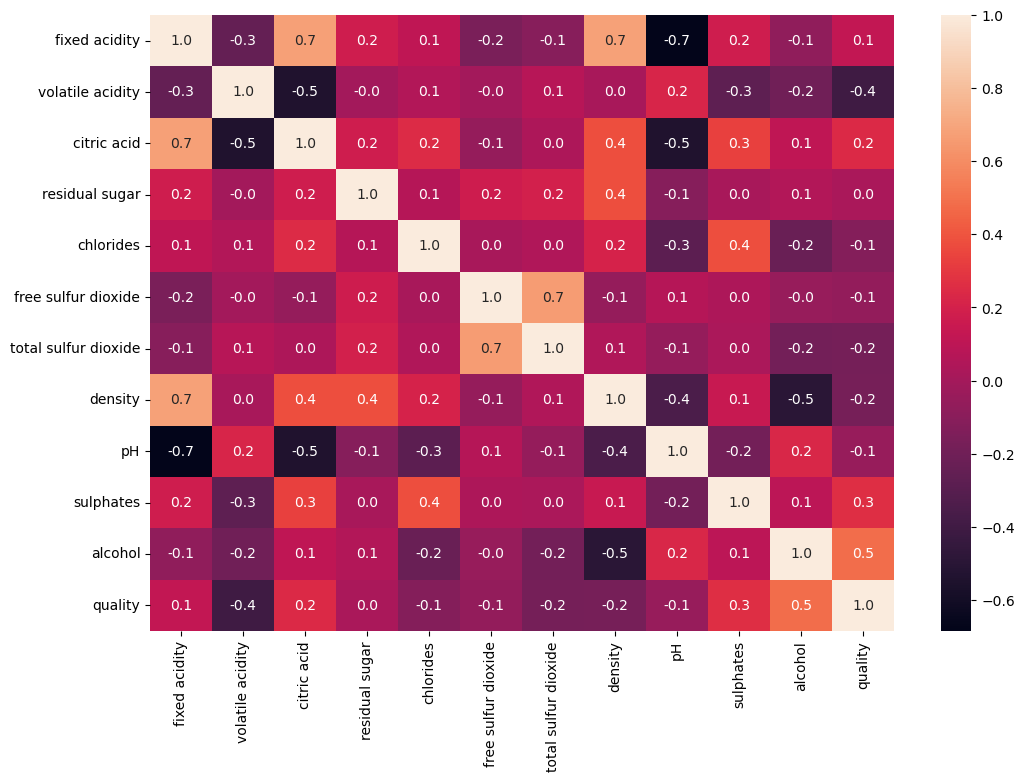

In [18]:
corr = df.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,fmt="0.1f")
plt.show()

**Your Analysis:**
From the corr we can see with quality...alcohol and volatile acidity has the most positive and neg corr...which is 0.5 and -0.4...also sulphate has 0.3 positive corr so relationship with quality is less pronounced...Higher alcohol content may contribute to the body and mouthfeel of wine...while excessive volatile acidity can produce undesirable vinegar like aromas and negatively affect its quality.


##### Question 3: Implement the standard machine learning workflow by creating appropriate train-test splits and building your decision tree model. Use a 70/30 split for training and testing data, and ensure you're using all relevant features identified in your data cleaning process.

In [20]:
X = df.drop(columns=["quality"])
y = df["quality"]
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=0)

In [21]:
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [29]:
y_pred=model.predict(x_test)
y_pred

array([5, 6, 7, 5, 8, 5, 6, 5, 5, 8, 7, 5, 6, 7, 7, 6, 7, 6, 6, 6, 6, 5,
       6, 5, 7, 6, 5, 5, 7, 6, 6, 6, 5, 6, 5, 5, 5, 6, 5, 5, 6, 5, 5, 6,
       5, 6, 6, 5, 5, 6, 7, 5, 5, 7, 5, 5, 5, 4, 5, 5, 7, 6, 5, 6, 5, 5,
       5, 7, 6, 5, 5, 5, 5, 6, 6, 7, 6, 6, 4, 5, 5, 6, 5, 6, 6, 4, 5, 6,
       5, 6, 6, 6, 6, 6, 6, 6, 6, 7, 5, 5, 6, 4, 7, 5, 5, 5, 5, 6, 6, 5,
       6, 6, 6, 5, 6, 6, 6, 7, 7, 5, 5, 6, 6, 6, 5, 6, 5, 6, 5, 6, 6, 5,
       6, 6, 6, 5, 6, 5, 6, 5, 5, 6, 6, 5, 5, 6, 6, 5, 7, 7, 6, 6, 5, 5,
       5, 5, 5, 6, 6, 6, 6, 5, 5, 6, 5, 7, 5, 5, 4, 5, 5, 6, 6, 5, 5, 7,
       6, 6, 6, 5, 5, 5, 7, 6, 7, 5, 7, 6, 5, 5, 6, 6, 5, 5, 4, 8, 6, 5,
       4, 5, 6, 5, 6, 5, 5, 5, 5, 7, 6, 6, 6, 5, 5, 5, 6, 7, 5, 6, 5, 5,
       6, 6, 6, 5, 5, 5, 7, 7, 7, 7, 5, 6, 8, 6, 5, 6, 7, 5, 7, 7, 6, 6,
       6, 6, 5, 6, 6, 6, 7, 5, 5, 5, 6, 5, 5, 7, 5, 6, 6, 5, 6, 5, 5, 5,
       5, 5, 7, 5, 5, 5, 5, 6, 5, 7, 6, 6, 5, 6, 5, 5, 5, 5, 6, 5, 5, 5,
       6, 6, 6, 5, 5, 5, 5, 5, 6, 8, 5, 5, 5, 5, 5,

##### Question 4: Test your trained model's practical applicability by predicting the quality of a specific wine sample. Consider the wine with the characteristics shown below and interpret what quality rating your model assigns to it.

**Wine Sample Analysis:**
This wine sample represents a real-world scenario where you'd use your model to assess an unknown wine. Examine how the individual feature values might contribute to the final quality prediction.

| fixed acidity | volatile acidity | citric acid | residual sugar | chlorides | free sulfur dioxide | total sulfur dioxide | density | pH | sulphates | alcohol | Id |
| --- | --- | --- |--- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5.9 | 0.645 | 0.12 | 2.0 | 0.075 | 32.0 | 44.0 | 0.9954 | 3.57 | 0.71 | 10.2 | 178 |

In [24]:
WineSample = pd.DataFrame([{"fixed acidity":5.9,"volatile acidity":0.645,"citric acid":0.12,"residual sugar":2.0,"chlorides":0.075,"free sulfur dioxide":32.0,"total sulfur dioxide": 44.0,"density": 0.9954,"pH": 3.57,"sulphates": 0.71,"alcohol": 10.2}])
pred = model.predict(WineSample)
print(pred)

[5]


**Your Interpretation:**
the model predicts the quality 5 by using the sample test..which is a moderate quality rating...

## 5.4 Comprehensive Model Evaluation

Model performance evaluation is critical for understanding how well our decision tree generalizes to unseen data. We'll examine multiple metrics to gain a complete picture of our model's strengths and weaknesses.

Predictions alone don't tell us much about our model's reliability. We need quantitative metrics to assess performance objectively and identify areas for improvement.

##### Question 5: Calculate and interpret both accuracy and precision metrics for your model. Evaluate whether these performance scores indicate a reliable model for wine quality prediction. Support your analysis by explaining what these metrics mean in the context of our specific problem.

In [34]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred,average="weighted")
print(f"accuracy:{accuracy}\nprecision:{precision}")

accuracy:0.5714285714285714
precision:0.5732672673710225


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Your Analysis:**
the accuracy and the precision score of the decision tree model is 57.14% and 57.32%...which is a moderate rate of correct prediction
- limited predictive performance
- not sufficient enough

##### Question 6: Create and analyze a confusion matrix visualization for your model. Explain how the visual patterns in this matrix confirm or contradict your accuracy and precision findings from the previous question.

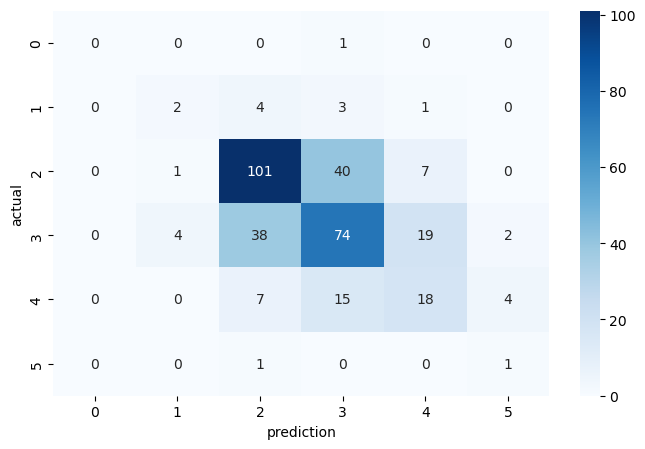

In [41]:
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(8,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("prediction")
plt.ylabel("actual")
plt.show()

**Your Visual Analysis:**
from the heatmap we can see the decision tree model moderately predicted some wine quality...as example it predicted 101 correct prediction for quality 2 but on the other hand it also predicted 40 quality 2 to quality 3 which were wrong while 38 as quality 2 but the actual is wuality 3...also 74 prediction for right quality 3 as well.
- this pattern also supports accuracy of 57.14% moderate score and precision score of 57.32%

##### Question 7: Investigate an important aspect of confusion matrix interpretation in multi-class problems. Analyze the relationship between the matrix indices and actual quality ratings, and explain why understanding label encoding is crucial for proper interpretation. 

**Investigation Hint:** Use pandas methods to examine the distribution of actual and predicted values, then consult the sklearn documentation to understand how confusion matrices handle class labels.

In [42]:
print("actual quality:",y_test.value_counts().sort_index())

actual quality: quality
3      1
4     10
5    149
6    137
7     44
8      2
Name: count, dtype: int64


In [44]:
print("predicted quality:",pd.Series(y_pred).value_counts().sort_index())

predicted quality: 4      7
5    151
6    133
7     45
8      7
Name: count, dtype: int64


In [ ]:
labels = sorted(set(y_test) | set(y_pred))
print("Class labels:", labels)

Class labels: [3, 4, 5, 6, 7, 8]


**Your Findings:**

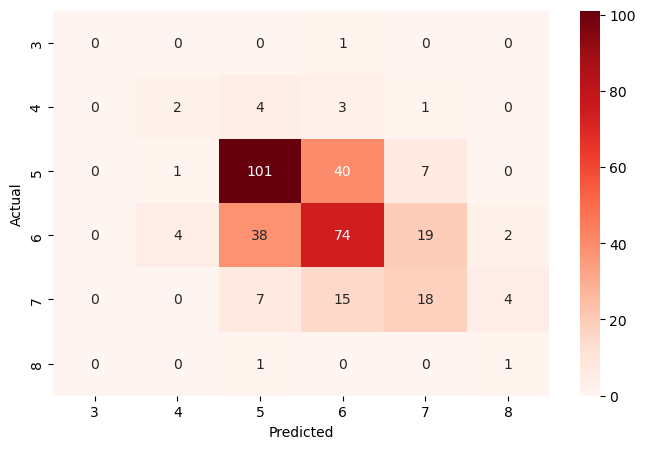

In [49]:
cm = confusion_matrix(y_test,y_pred,labels=labels)
plt.figure(figsize=(8,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Reds",xticklabels=labels,yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()